# Business visualizations for food demand

This notebook creates four finding-led charts from the verified Task 3 summaries and the prepared training observations. It does not read from or write to `data/raw/`, and it saves new chart filenames without replacing the existing Task 3 figures.

Run cells from top to bottom. Validation checks compare chart inputs to the existing CSV summaries and verify every exported PNG.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from PIL import Image
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in candidates if (path / 'reports' / 'weekly_demand.csv').is_file()), None)
if project_root is None:
    raise FileNotFoundError('Could not locate reports/weekly_demand.csv from the notebook working directory.')
reports_dir = project_root / 'reports'
figures_dir = reports_dir / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
prepared_path = project_root / 'data' / 'processed' / 'prepared_train.csv'
if not prepared_path.is_file():
    raise FileNotFoundError(f'Prepared training dataset not found: {prepared_path}')

weekly = pd.read_csv(reports_dir / 'weekly_demand.csv')
categories = pd.read_csv(reports_dir / 'category_demand.csv')
promotion_summary = pd.read_csv(reports_dir / 'promotion_demand_tests.csv')
discount_summary = pd.read_csv(reports_dir / 'discount_demand_spearman.csv')
prepared = pd.read_csv(prepared_path)
required_columns = {'week', 'center_id', 'meal_id', 'num_orders', 'base_price', 'checkout_price', 'emailer_for_promotion'}
if not required_columns.issubset(prepared.columns):
    raise ValueError(f'Prepared data is missing required columns: {sorted(required_columns - set(prepared.columns))}')
if prepared[list(required_columns)].isna().any().any():
    raise ValueError('Required prepared-data columns contain missing values; chart inputs need explicit handling.')

expected_total = int(prepared['num_orders'].sum())
assert int(weekly['total_orders'].sum()) == expected_total, 'Weekly summary does not reconcile to prepared training orders.'
assert int(categories['total_orders'].sum()) == expected_total, 'Category summary does not reconcile to prepared training orders.'
assert prepared['emailer_for_promotion'].isin([0, 1]).all(), 'Email promotion flag is not binary.'
print(f'Loaded {len(prepared):,} prepared observations; total orders={expected_total:,}; observed weeks={weekly.week.nunique():,}.')
print('Existing Task 3 weekly and category CSV totals reconcile with the prepared dataset.')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 14, 'axes.labelsize': 11, 'figure.dpi': 120})
generated_figures = []

Loaded 456,548 prepared observations; total orders=119,557,485; observed weeks=145.
Existing Task 3 weekly and category CSV totals reconcile with the prepared dataset.


## Chart 1 — Weekly demand trend

**Purpose:** show the weekly order totals and call out the observed peak in the title. Values come from the Task 3 `weekly_demand.csv`; the total is reconciled against the prepared data. This is descriptive and does not explain why demand fluctuates.

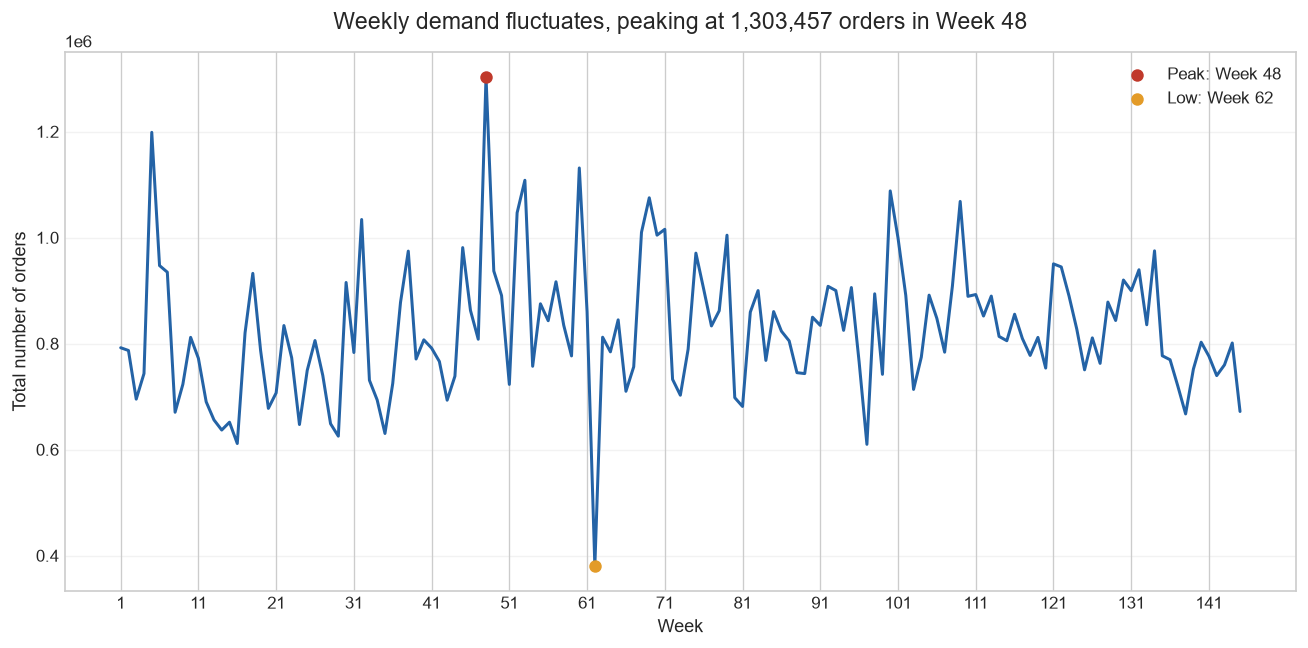

Interpretation: the observed maximum is Week 48 (1,303,457); the minimum is Week 62 (380,065). The chart does not establish causes.


In [2]:
peak = weekly.loc[weekly['total_orders'].idxmax()]
trough = weekly.loc[weekly['total_orders'].idxmin()]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(weekly['week'], weekly['total_orders'], color='#2463a6', linewidth=1.8)
ax.scatter([peak['week']], [peak['total_orders']], color='#c0392b', zorder=3, s=42, label=f"Peak: Week {int(peak['week'])}")
ax.scatter([trough['week']], [trough['total_orders']], color='#e39b28', zorder=3, s=42, label=f"Low: Week {int(trough['week'])}")
ax.set_title(f"Weekly demand fluctuates, peaking at {int(peak['total_orders']):,} orders in Week {int(peak['week'])}", pad=14)
ax.set_xlabel('Week')
ax.set_ylabel('Total number of orders')
ax.set_xticks(np.arange(weekly['week'].min(), weekly['week'].max() + 1, 10))
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
path = figures_dir / 'weekly_demand_trend.png'
fig.savefig(path, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
generated_figures.append(path)
print(f"Interpretation: the observed maximum is Week {int(peak['week'])} ({int(peak['total_orders']):,}); the minimum is Week {int(trough['week'])} ({int(trough['total_orders']):,}). The chart does not establish causes.")

## Chart 2 — Demand concentration by category

**Purpose:** rank every category by total orders, highlight the smallest leading set that reaches 80%, and label cumulative contribution. The threshold is descriptive concentration only; it does not imply that category membership causes demand.

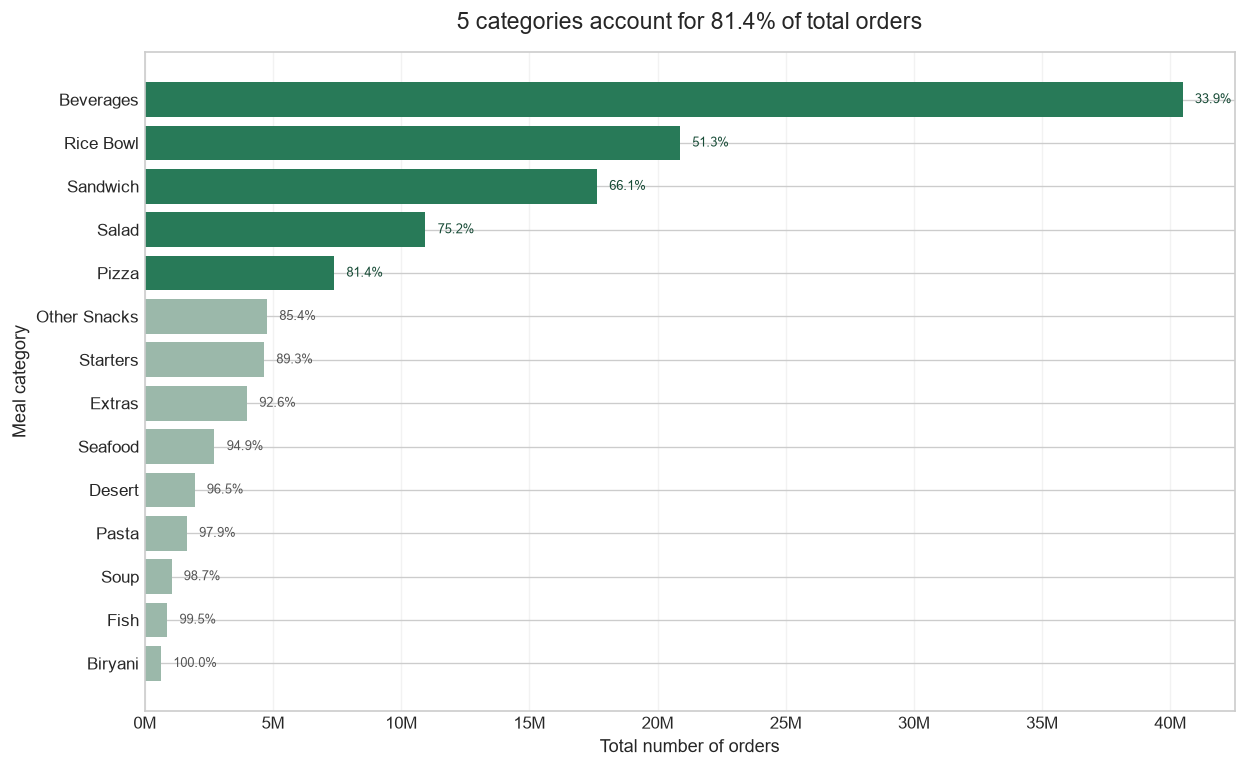

Interpretation: the top 5 categories contribute 81.4% of recorded orders; green bars mark the leading categories needed to reach 80%.


In [3]:
categories = categories.sort_values(['total_orders', 'category'], ascending=[False, True]).reset_index(drop=True)
categories['verified_cumulative_share'] = categories['total_orders'].cumsum() / expected_total
threshold_count = int(categories['verified_cumulative_share'].lt(0.80).sum() + 1)
selected_share = float(categories.loc[:threshold_count - 1, 'total_orders'].sum() / expected_total)
assert np.allclose(categories['verified_cumulative_share'], categories['cumulative_share'], rtol=0, atol=1e-8), 'Recomputed category cumulative shares do not match Task 3 summary.'
colors = ['#287a58' if index < threshold_count else '#9bb8aa' for index in range(len(categories))]
fig, ax = plt.subplots(figsize=(10.5, 6.5))
bars = ax.barh(categories['category'], categories['total_orders'], color=colors)
ax.invert_yaxis()
ax.set_title(f"{threshold_count} categories account for {selected_share:.1%} of total orders", pad=14)
ax.set_xlabel('Total number of orders')
ax.set_ylabel('Meal category')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value / 1_000_000:.0f}M'))
ax.grid(axis='x', alpha=0.25)
for index, (bar, row) in enumerate(zip(bars, categories.itertuples(index=False))):
    ax.text(bar.get_width() + expected_total * 0.004, bar.get_y() + bar.get_height() / 2,
            f'{row.verified_cumulative_share:.1%}', va='center', fontsize=8,
            color='#174b36' if index < threshold_count else '#555555')
fig.tight_layout()
path = figures_dir / 'category_demand_concentration.png'
fig.savefig(path, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
generated_figures.append(path)
print(f'Interpretation: the top {threshold_count} categories contribute {selected_share:.1%} of recorded orders; green bars mark the leading categories needed to reach 80%.')

## Chart 3 — Orders with and without email promotion

**Purpose:** compare row-level order distributions for `emailer_for_promotion=0` and `=1`, restricted to meal-center pairs that appear in both states, consistent with Task 3. Observations are pooled across eligible pairs and weeks, so groups are row-weighted. A logarithmic y-axis makes the skewed distribution visible; labels show the actual group sample sizes. The title explicitly frames the difference as observational. Repeated observations within meal-center pairs mean this plot and the associated ordinary Mann–Whitney p-value are not causal or confirmatory evidence.

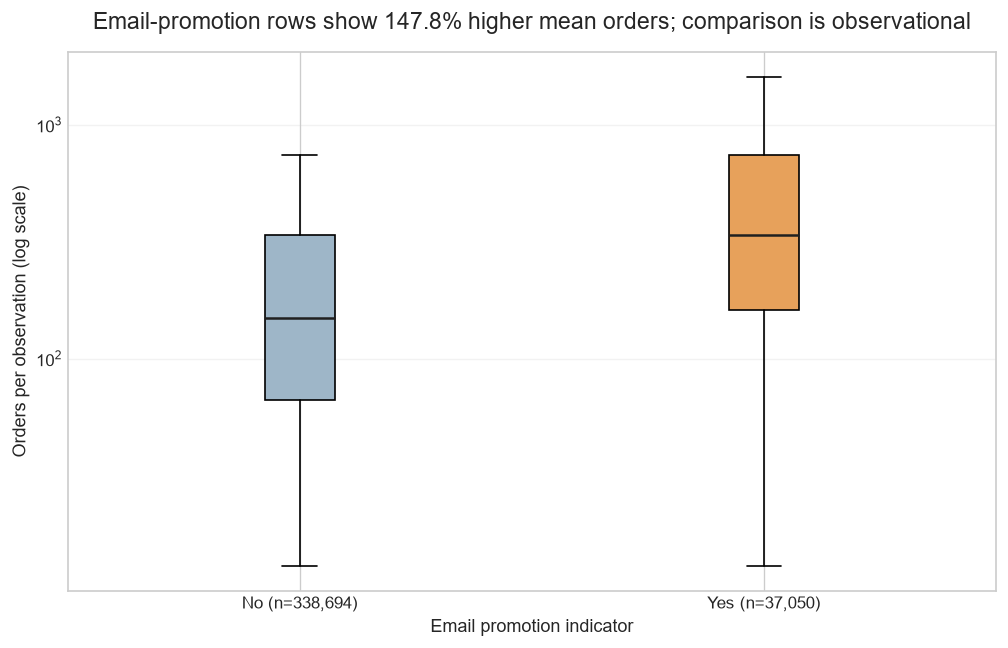

Interpretation: among 2,830 eligible meal-center pairs, mean orders were 254.64 without and 631.10 with the email indicator. Weekly rows repeat within pairs; the plot does not imply promotion caused the difference.


In [4]:
email_summary = promotion_summary.loc[promotion_summary['indicator'].eq('emailer_for_promotion')].set_index('promotion')
if not {'No', 'Yes'}.issubset(email_summary.index):
    raise ValueError('Task 3 promotion summary lacks No/Yes email promotion rows.')
pair_status = prepared.groupby(['meal_id', 'center_id'])['emailer_for_promotion'].nunique()
eligible_pairs = pair_status.index[pair_status.eq(2)]
pair_index = pd.MultiIndex.from_frame(prepared[['meal_id', 'center_id']])
eligible = prepared.loc[pair_index.isin(eligible_pairs), ['meal_id', 'center_id', 'week', 'emailer_for_promotion', 'num_orders']]
group_no = eligible.loc[eligible['emailer_for_promotion'].eq(0), 'num_orders']
group_yes = eligible.loc[eligible['emailer_for_promotion'].eq(1), 'num_orders']
assert len(eligible_pairs) == int(email_summary.loc['No', 'eligible_meal_center_pairs'])
assert len(group_no) == int(email_summary.loc['No', 'n']) and len(group_yes) == int(email_summary.loc['Yes', 'n'])
assert np.isclose(group_no.mean(), email_summary.loc['No', 'mean_orders'])
assert np.isclose(group_yes.mean(), email_summary.loc['Yes', 'mean_orders'])
mean_difference = float(email_summary.loc['Yes', 'mean_difference_percent'])
fig, ax = plt.subplots(figsize=(8.5, 5.5))
bp = ax.boxplot([group_no, group_yes], tick_labels=[f'No (n={len(group_no):,})', f'Yes (n={len(group_yes):,})'],
                showfliers=False, patch_artist=True, medianprops={'color': '#202020', 'linewidth': 1.5})
for patch, color in zip(bp['boxes'], ['#9eb6c8', '#e7a15b']):
    patch.set_facecolor(color)
ax.set_yscale('log')
ax.set_title(f"Email-promotion rows show {mean_difference:.1f}% higher mean orders; comparison is observational", pad=14)
ax.set_xlabel('Email promotion indicator')
ax.set_ylabel('Orders per observation (log scale)')
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
path = figures_dir / 'promotion_order_distribution.png'
fig.savefig(path, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
generated_figures.append(path)
print(f'Interpretation: among {len(eligible_pairs):,} eligible meal-center pairs, mean orders were {group_no.mean():.2f} without and {group_yes.mean():.2f} with the email indicator. Weekly rows repeat within pairs; the plot does not imply promotion caused the difference.')

## Chart 4 — Signed discount rate versus demand

**Purpose:** show the association between signed row-level discount rate and orders. The rate is `(base_price - checkout_price) / base_price`; prices above base price remain negative. Only rows with finite values and positive base prices are plotted. All valid observations are shown with transparency and rasterization, not sampled. The title uses the verified Spearman correlation. No fitted line is added: the title and correlation summarize the monotonic association, while avoiding a linear fit that could imply a model or causal effect. Statistical significance does not imply a strong relationship or causation.

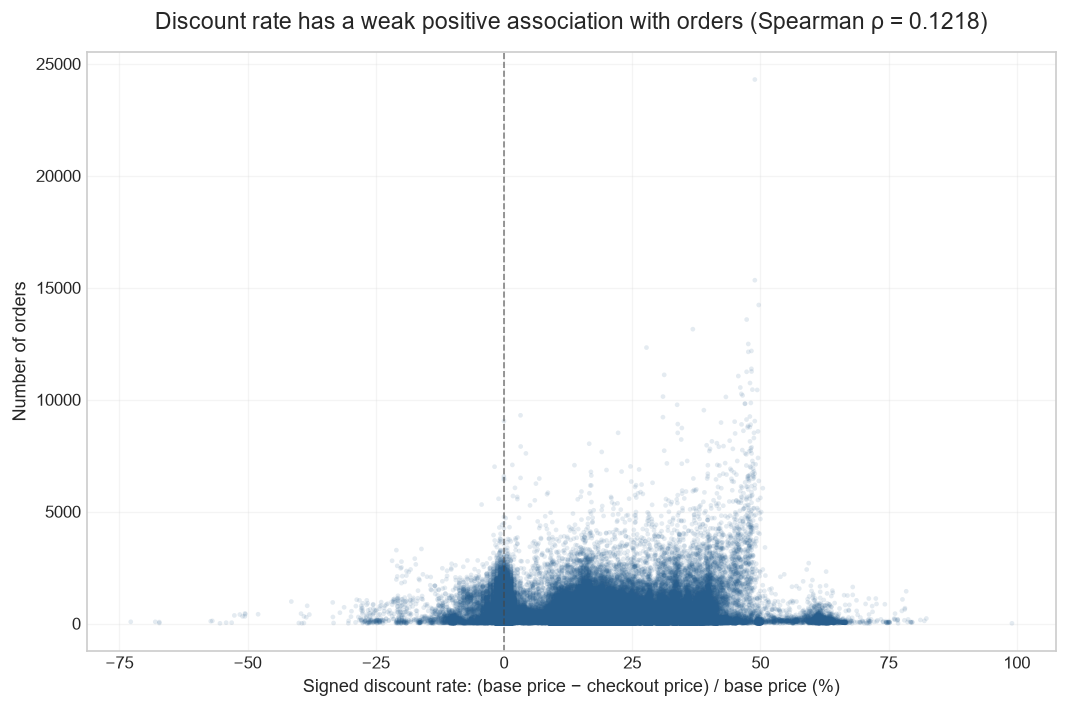

Interpretation: Spearman ρ=0.1218 for 456,548 valid rows; 116,101 negative-rate rows are retained. This is a weak association, not evidence that discounts cause demand.


In [5]:
valid_discount = (prepared['base_price'].gt(0) & np.isfinite(prepared['base_price']) &
                  np.isfinite(prepared['checkout_price']) & np.isfinite(prepared['num_orders']))
discount_data = prepared.loc[valid_discount, ['base_price', 'checkout_price', 'num_orders']].copy()
discount_data['signed_discount_rate'] = (discount_data['base_price'] - discount_data['checkout_price']) / discount_data['base_price']
rho = float(discount_summary.loc[0, 'spearman_rho'])
assert len(discount_data) == int(discount_summary.loc[0, 'n']), 'Valid plotted sample size differs from Task 3 discount summary.'
assert int((~valid_discount).sum()) == int(discount_summary.loc[0, 'excluded_rows']), 'Invalid discount exclusions differ from Task 3 summary.'
negative_rate_count = int(discount_data['signed_discount_rate'].lt(0).sum())
assert negative_rate_count == int(prepared['checkout_price'].gt(prepared['base_price']).sum()), 'Negative signed discount rates were clipped or lost.'
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(discount_data['signed_discount_rate'] * 100, discount_data['num_orders'],
           s=8, alpha=0.12, color='#275d8c', edgecolors='none', rasterized=True)
ax.axvline(0, color='#444444', linewidth=1, linestyle='--', alpha=0.65)
ax.set_title(f'Discount rate has a weak positive association with orders (Spearman ρ = {rho:.4f})', pad=14)
ax.set_xlabel('Signed discount rate: (base price − checkout price) / base price (%)')
ax.set_ylabel('Number of orders')
ax.grid(alpha=0.2)
fig.tight_layout()
path = figures_dir / 'discount_vs_demand.png'
fig.savefig(path, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
generated_figures.append(path)
print(f'Interpretation: Spearman ρ={rho:.4f} for {len(discount_data):,} valid rows; {negative_rate_count:,} negative-rate rows are retained. This is a weak association, not evidence that discounts cause demand.')

## Validation and limitations

The weekly and category charts use Task 3 aggregate CSVs and reconcile their order totals to the prepared observations. The promotion chart reconstructs the common-support meal-center filter and checks group sizes and means against the Task 3 promotion summary. The discount chart verifies valid-row counts, exclusions, and retention of negative signed rates against its summary. All figures use the same Matplotlib style, explicit labels, finding-led titles, tight layouts, and 180 DPI export.

Limitations: the promotion comparison is observational and pools repeated weekly rows; the ordinary Mann–Whitney p-value is not confirmatory under within-pair dependence. Discount-demand correlation is weak and cannot separate discounts from promotions, homepage placement, or time-related confounding. These charts describe observed data and do not establish causality.

In [6]:
expected_names = ['weekly_demand_trend.png', 'category_demand_concentration.png',
                  'promotion_order_distribution.png', 'discount_vs_demand.png']
assert [path.name for path in generated_figures] == expected_names
for filename in expected_names:
    image_path = figures_dir / filename
    if not image_path.is_file() or image_path.stat().st_size == 0:
        raise FileNotFoundError(f'Chart is missing or empty: {image_path}')
    with Image.open(image_path) as image:
        image.verify()
    with Image.open(image_path) as image:
        if image.format != 'PNG' or image.width < 1 or image.height < 1:
            raise ValueError(f'Invalid PNG image: {image_path}')
        print(f'{filename}: valid {image.format}, {image.width}x{image.height}, {image_path.stat().st_size:,} bytes.')
print(f'All {len(expected_names)} requested charts were created and opened successfully in {figures_dir.relative_to(project_root)}.')

weekly_demand_trend.png: valid PNG, 1962x971, 152,092 bytes.
category_demand_concentration.png: valid PNG, 1868x1151, 90,823 bytes.
promotion_order_distribution.png: valid PNG, 1512x971, 45,913 bytes.
discount_vs_demand.png: valid PNG, 1604x1061, 207,690 bytes.
All 4 requested charts were created and opened successfully in reports\figures.
